# Kết quả so sánh đầy đủ năm mô hình

Notebook tự đợi notebook 09 hoàn tất gộp đủ ma trận. Số liệu dưới đây chỉ được tạo từ kết quả nghiên cứu COMPLETE, không dùng pilot. Chênh lệch là structural trừ từng đối thủ. Bốn set dùng lại xe; không coi là bốn xe đích độc lập.

In [1]:
from pathlib import Path
import json,time
CODE=Path(r'F:/00_Research/code')
STATUS=CODE/'notebooks/09_assoc_cpu_acceleration.execution.json'
while True:
    state=json.loads(STATUS.read_text()) if STATUS.exists() else {}
    if state.get('status')=='COMPLETE':break
    if state.get('status')=='FAILED':raise RuntimeError(state.get('error','Notebook 09 failed'))
    print('Đang chờ đủ kết quả GPU/CPU và kiểm tra gộp...',flush=True)
    time.sleep(30)
RESULTS=CODE/'results/comparison_merged_fast'
coverage=json.loads((RESULTS/'coverage.json').read_text())
assert coverage['status']=='COMPLETE_MATRIX' and coverage['cells']==60
print(json.dumps(coverage,ensure_ascii=False,indent=2))

{
  "status": "COMPLETE_MATRIX",
  "cells": 60,
  "methods": [
    "assoc_rules_crysys",
    "canbertplus",
    "canlp",
    "raw_transformer",
    "structural_transformer"
  ],
  "analysis_code_sha256": "a7ee0e2f1c5ebd6adb8357a4a16f39797eff9b79d698d561aef8d3d4ec75becc",
  "note": "Original execution manifests retained. Native code/data/config/environment must match; only declared exact-call caching backend may differ."
}


In [2]:
import pandas as pd
from IPython.display import display, Image
paired=pd.read_csv(RESULTS/'paired_by_set.csv')
display(paired[paired.condition.isin(['B','D'])])
display(pd.read_csv(RESULTS/'paired_equal_set_mean.csv',header=[0,1]))

,opponent,condition,set,Recall,FAR_per_100k,Attack_F1,AP
4,assoc_rules_crysys,B,set_01,0.494978,32.136345,0.587030,0.767838
5,assoc_rules_crysys,B,set_02,0.966253,85422.222222,0.044091,0.398081
6,assoc_rules_crysys,B,set_03,0.974077,86686.546101,0.169220,0.637266
7,assoc_rules_crysys,B,set_04,0.517874,37704.918033,0.173573,0.182235
12,assoc_rules_crysys,D,set_01,0.000479,77.433700,0.000853,0.006173
13,assoc_rules_crysys,D,set_02,0.847826,84374.463160,0.029126,0.071073
14,assoc_rules_crysys,D,set_03,0.946897,91180.007425,0.383330,0.323868
15,assoc_rules_crysys,D,set_04,0.782740,42941.586651,0.414404,0.576943
24,canbertplus,B,set_01,-0.077975,-61439.274946,0.490260,0.781791
25,canbertplus,B,set_02,-0.032196,-14197.745572,0.005683,0.355506


Unnamed: 0_level_0 Unnamed: 1_level_0    Recall        FAR_per_100k        \
    Unnamed: 0_level_1 Unnamed: 1_level_1      mean count          mean count   
0             opponent          condition       NaN   NaN           NaN   NaN   
1   assoc_rules_crysys                  A  0.588594   4.0     81.665712   4.0   
2   assoc_rules_crysys                  B  0.738296   4.0  52461.455675   4.0   
3   assoc_rules_crysys                  C  0.223050   4.0     75.822011   4.0   
4   assoc_rules_crysys                  D  0.644486   4.0  54643.372734   4.0   
5   assoc_rules_crysys         validation  0.559429   4.0     90.543754   4.0   
6          canbertplus                  A  0.204265   4.0      2.395254   4.0   
7          canbertplus                  B  0.098817   4.0 -12382.392482   4.0   
8          canbertplus                  C  0.119301   4.0     13.281727   4.0   
9          canbertplus                  D  0.089588   4.0    129.921127   4.0   
10         canbertplus         validation  0.319474   4.0     34.435335   4.0   
11               canlp                  A  0.465783   4.0     53.298036   4.0   
12               canlp                  B  0.452862   4.0  22765.571470   4.0   
13               canlp                  C  0.221003   4.0   -329.665607   4.0   
14               canlp                  D  0.395338   4.0  29191.182127   4.0   
15               canlp         validation  0.365732   4.0     59.888664   4.0   
16     raw_transformer                  A -0.028100   4.0    -34.105937   4.0   
17     raw_transformer                  B -0.115854   4.0 -12839.952991   4.0   
18     raw_transformer                  C  0.012990   4.0    -16.101290   4.0   
19     raw_transformer                  D -0.016947   4.0 -13339.512454   4.0   
20     raw_transformer         validation  0.083088   4.0     -0.646315   4.0   

   Attack_F1              AP        
        mean count      mean count  
0        NaN   NaN       NaN   NaN  
1   0.707173   4.0  0.414548   4.0  
2   0.243478   4.0  0.496355   4.0  
3   0.259997   4.0  0.119649   4.0  
4   0.206928   4.0  0.244514   4.0  
5   0.661136   4.0  0.426468   4.0  
6   0.249578   4.0  0.214877   4.0  
7   0.184216   4.0  0.458448   4.0  
8   0.113916   4.0  0.071054   4.0  
9   0.142528   4.0  0.204570   4.0  
10  0.329402   4.0  0.336446   4.0  
11  0.528246   4.0  0.200146   4.0  
12  0.210599   4.0  0.501219   4.0  
13  0.256220   4.0  0.055548   4.0  
14  0.195038   4.0  0.245556   4.0  
15  0.414236   4.0  0.315984   4.0  
16 -0.018606   4.0  0.017140   4.0  
17 -0.056540   4.0  0.177359   4.0  
18  0.028621   4.0  0.026719   4.0  
19  0.085643   4.0  0.170886   4.0  
20  0.074098   4.0  0.091921   4.0

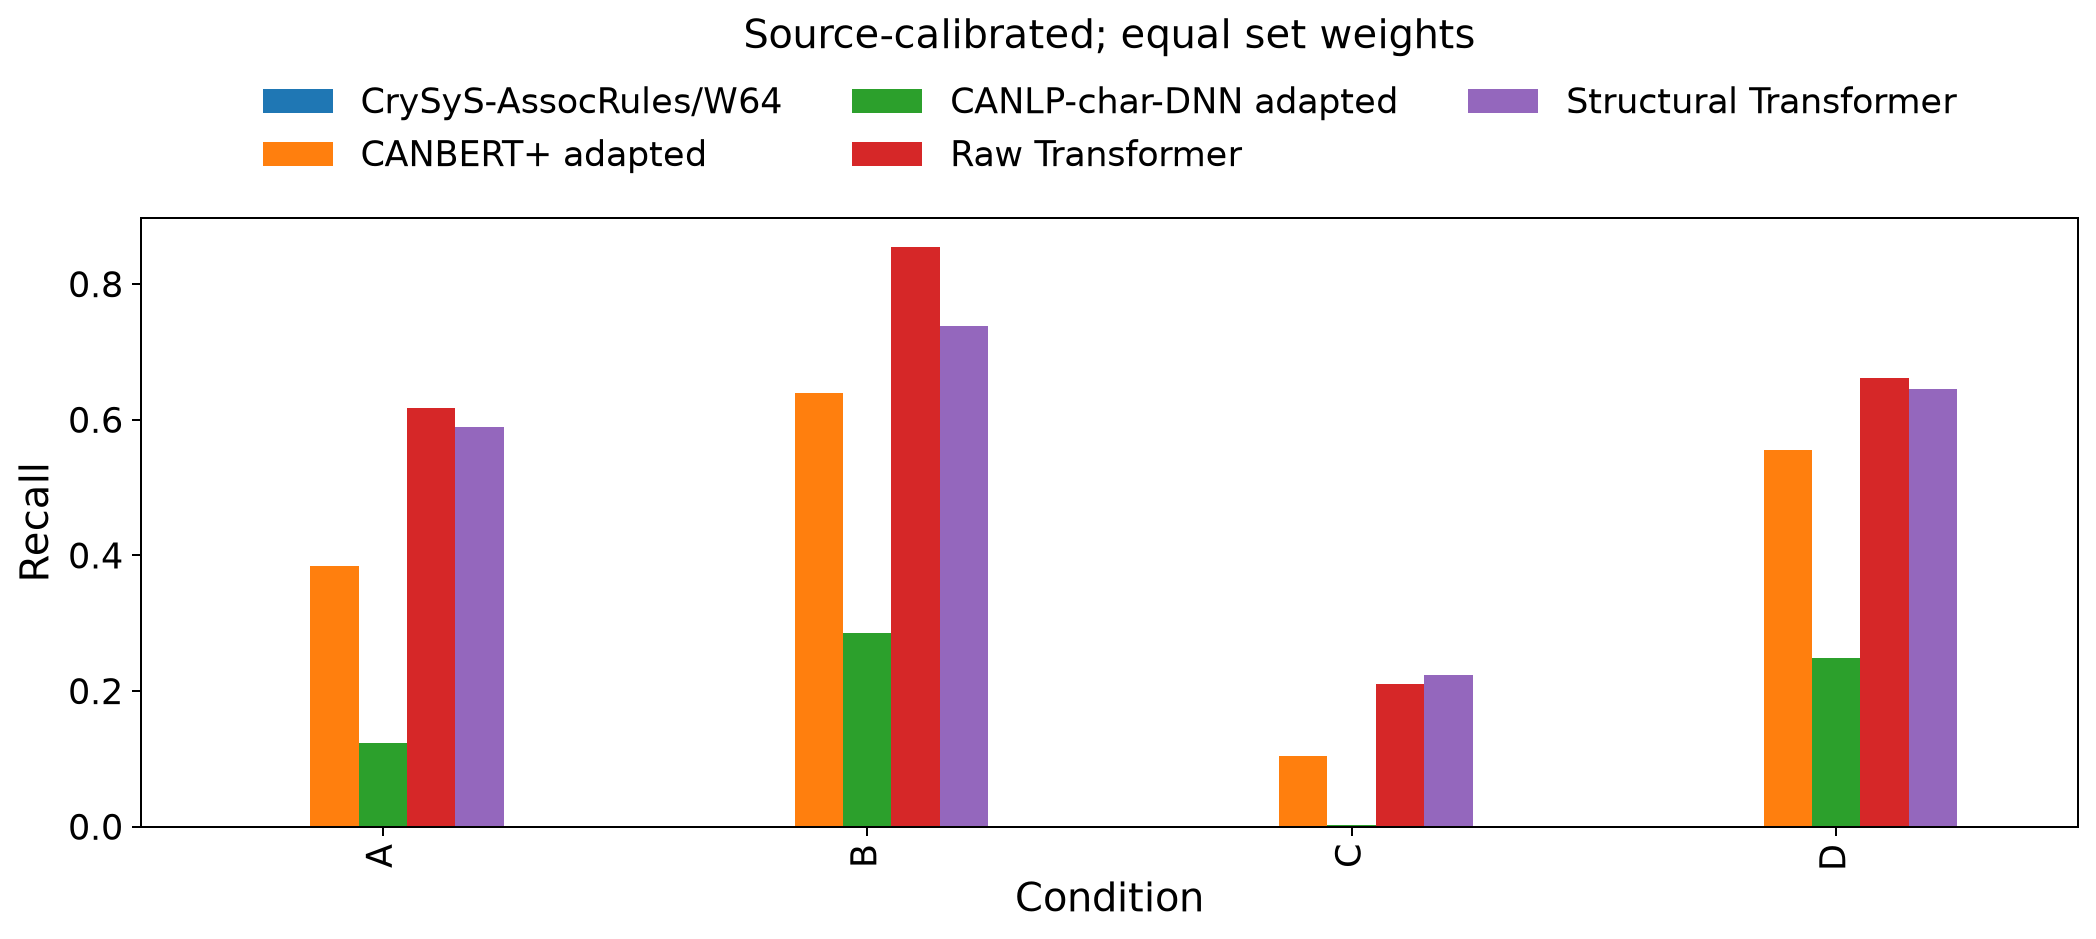

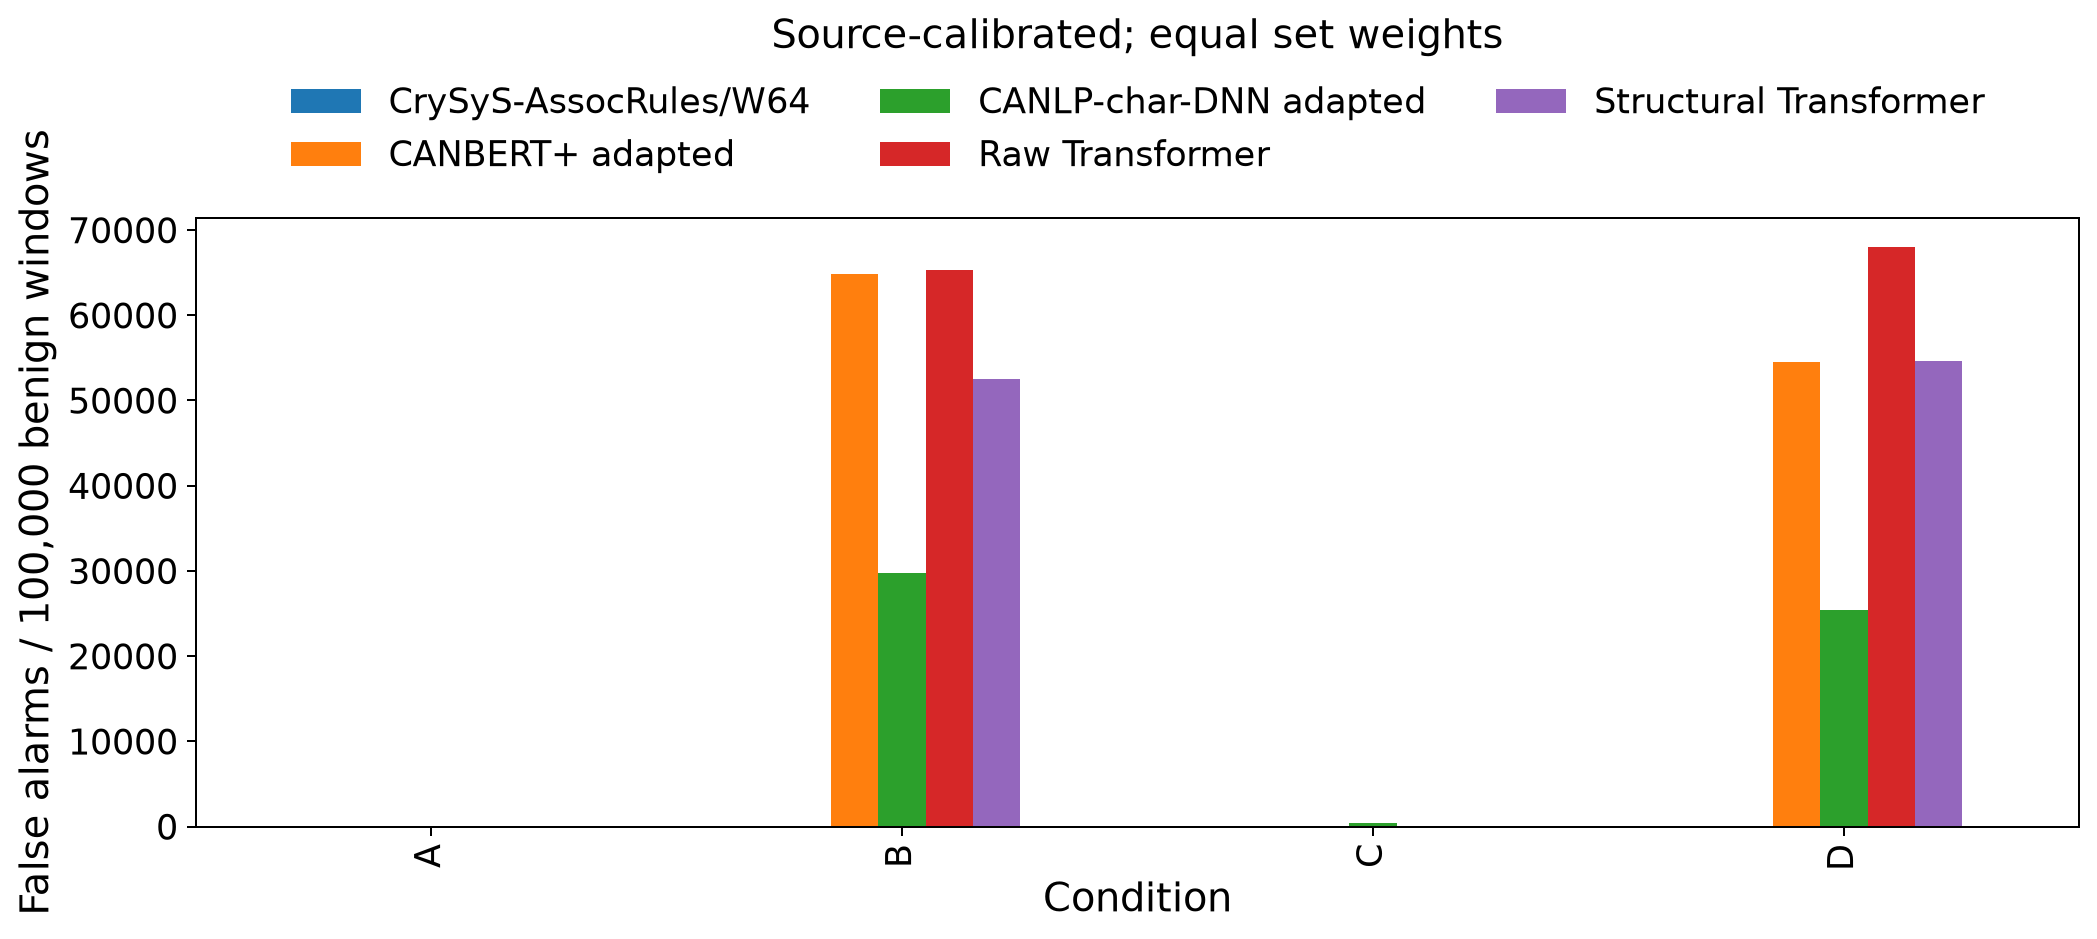

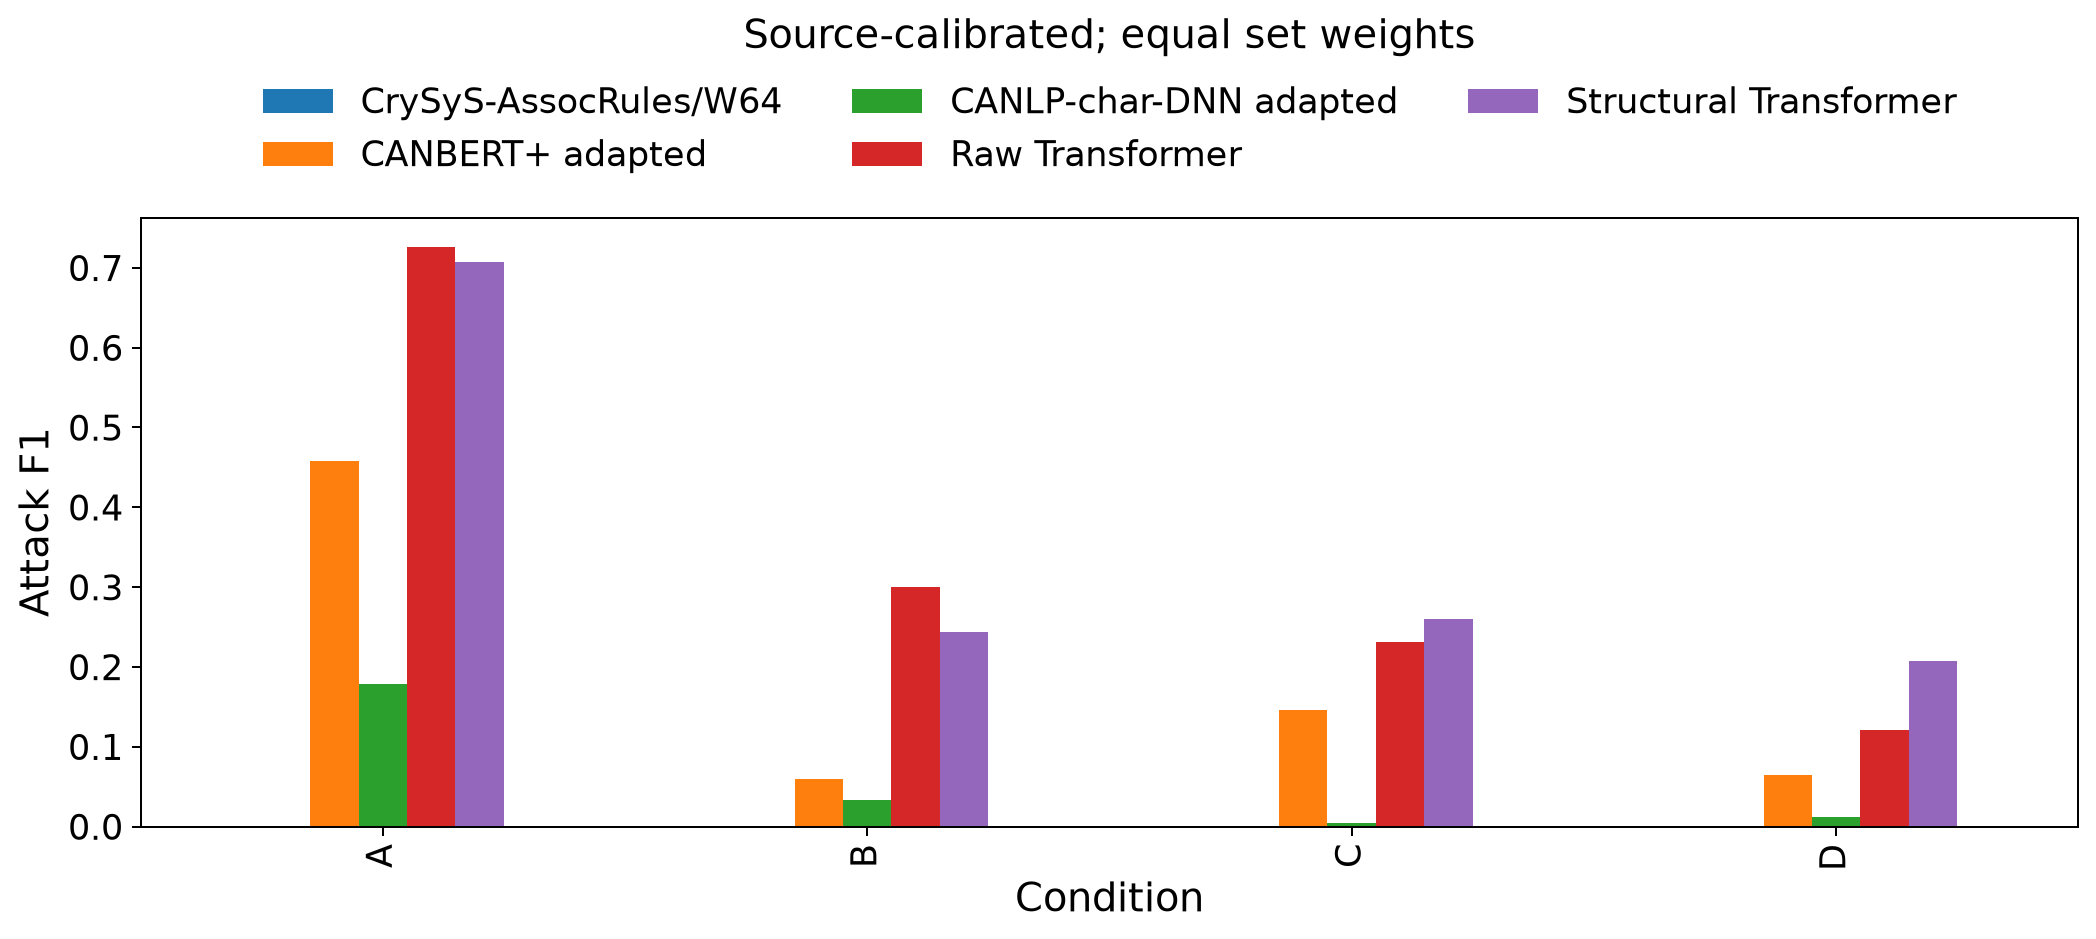

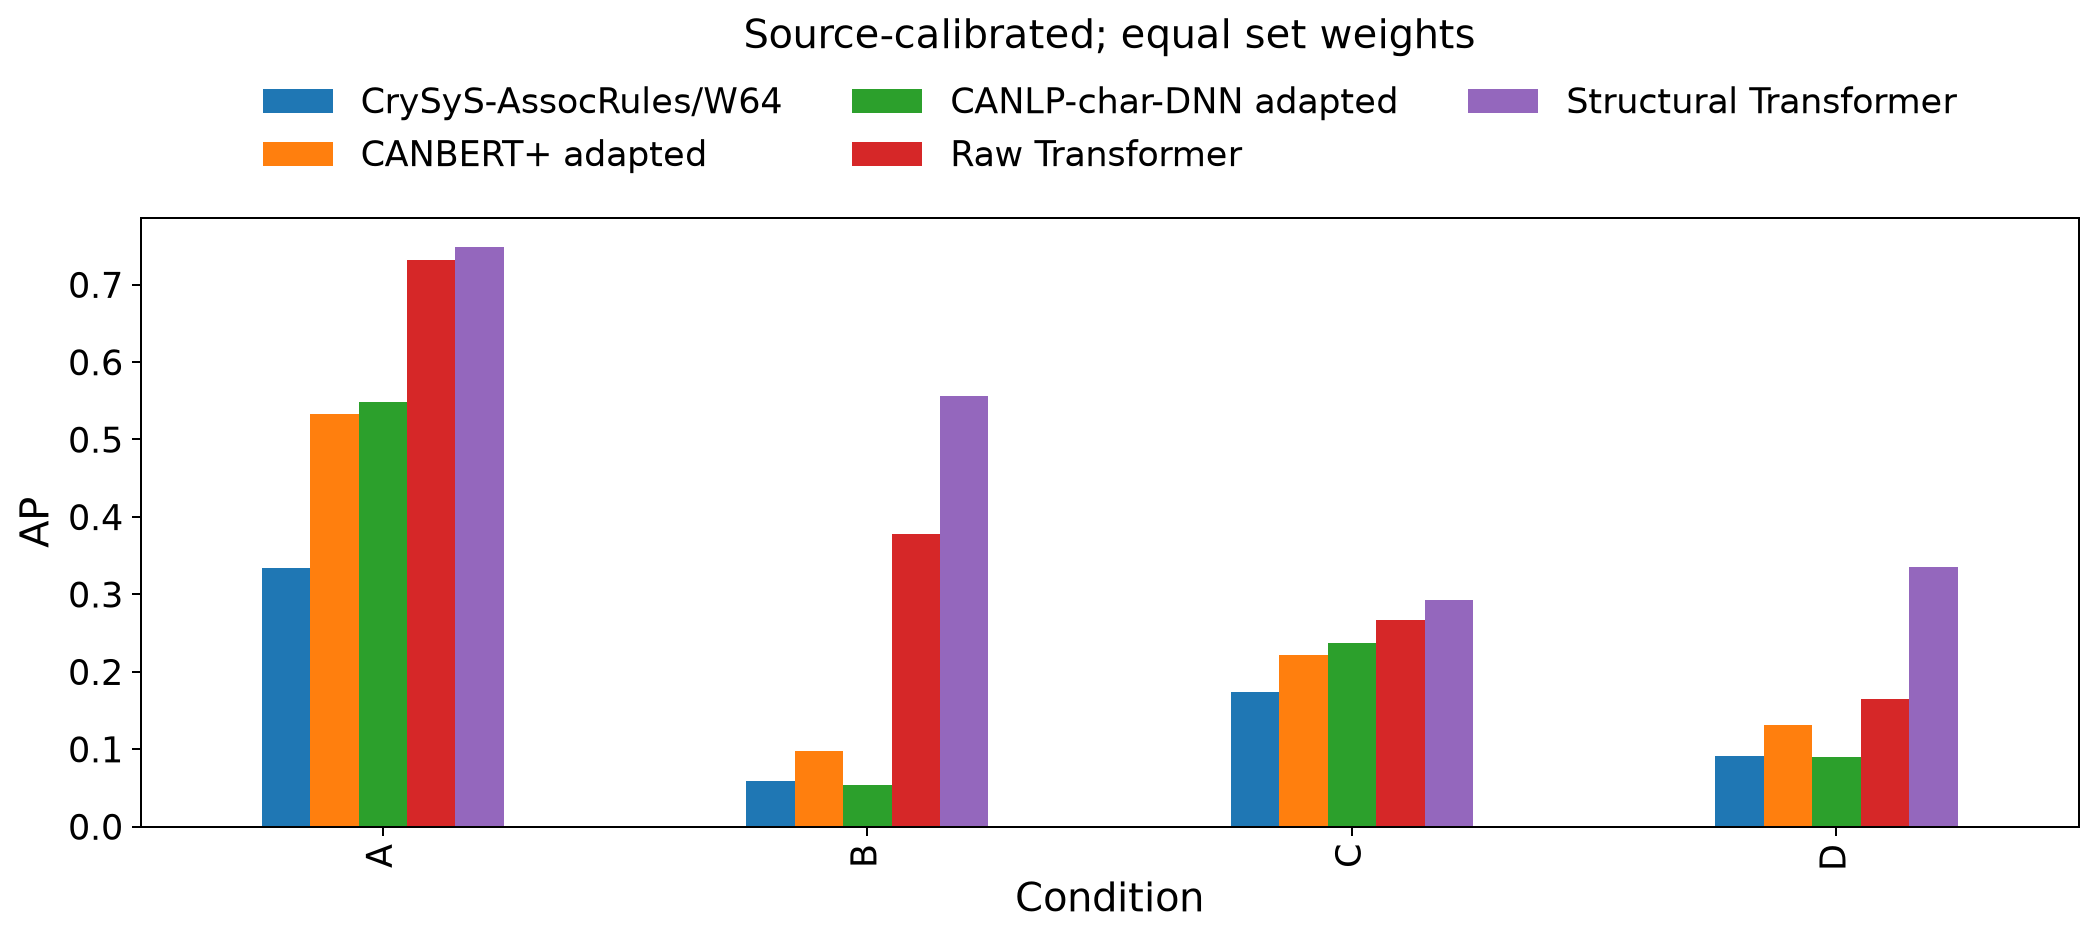

In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':16,'axes.titlesize':16,'axes.labelsize':16,'xtick.labelsize':14,'ytick.labelsize':14})
rows=pd.read_csv(RESULTS/'all_metrics.csv')
pooled=rows[(rows.file=='ALL')&(rows.operating_point=='source_calibrated')&rows.condition.isin(list('ABCD'))]
metrics=['Recall','FAR_per_100k','Attack_F1','AP']
per_set=pooled.groupby(['set','method','condition'])[metrics].mean()
mean=per_set.groupby(['method','condition'])[metrics].mean()
for metric in metrics:
    table=mean[metric].unstack('method').reindex(list('ABCD'))
    fig,ax=plt.subplots(figsize=(12,5.5))
    if table.notna().any().any():
        table=table.rename(columns={'raw_transformer':'Raw Transformer','structural_transformer':'Structural Transformer','canbertplus':'CANBERT+ adapted','canlp':'CANLP-char-DNN adapted','assoc_rules_crysys':'CrySyS-AssocRules/W64'})
        table.plot.bar(ax=ax)
        ax.legend(loc='lower center',bbox_to_anchor=(.5,1.02),ncol=3,fontsize=14,frameon=False,title=None)
    else:ax.text(.5,.5,'Metric unavailable',ha='center',va='center',transform=ax.transAxes)
    ax.set_xlabel('Condition');ax.set_ylabel('False alarms / 100,000 benign windows' if metric=='FAR_per_100k' else metric.replace('_',' '));ax.set_title('Source-calibrated; equal set weights',pad=68)
    fig.tight_layout();path=RESULTS/(metric+'.png');fig.savefig(path,dpi=180,bbox_inches='tight');plt.close(fig)
    display(Image(filename=str(path)))

Báo Recall cùng FAR và mẫu số. Recall tăng kèm FAR tăng là đánh đổi. Các khoảng capture bootstrap có điều kiện, không đại diện quần thể xe. Kiểm tra bảng đối chiếu supervision/budget/native adaptations trước khi viết kết luận vượt công trình khác.